In [1]:
!pip install deepchem rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 7.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 63.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [deepchem]


In [2]:
import sys
import deepchem as dc
import rdkit

print("Python:", sys.version)
print("DeepChem:", dc.__version__)
print("RDKit:", rdkit.__version__)

/usr/local/lib/python3.13/dist-packages/deepchem/feat/smiles_tokenizer.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
DeepChem: 2.5.0
RDKit: 2026.09.2


In [3]:
!pip install tf_keras

In [4]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = 'True'

In [5]:
import deepchem as dc
dc.__version__

'2.5.0'

In [6]:
tasks, datasets, transformers = (
    dc.molnet.load_bace_regression(
        featurizer="ECFP",
        splitter="scaffold",
        transformers=[]
    )
)

In [17]:
train, valid, test = datasets

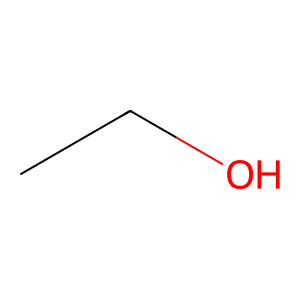

In [15]:
from rdkit import Chem
from rdkit.Chem import Draw

smiles = "CCO"

molecule = Chem.MolFromSmiles(smiles)
display(Draw.MolToImage(molecule))

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.concat([
    pd.DataFrame({
        "smiles": ds.ids,
        "pIC50": ds.y.flatten(),
        "split": split_name
    })
    for split_name, ds in [
        ("train", train),
        ("valid", valid),
        ("test", test)
    ]
], ignore_index=True)

print(df.head())
print(df["pIC50"].describe())

                                              smiles     pIC50  split
0  Fc1ccc(cc1C#CCCCF)[C@]1(N=C(N)N(C)C1=O)c1ccc(O...  7.853872  train
1  FCC#Cc1cc(ccc1)[C@]1(N=C(N)N(C)C1=O)c1ccc(OC(F...  8.000000  train
2  FCCC#Cc1cc(ccc1)[C@]1(N=C(N)N(C)C1=O)c1ccc(OC(...  8.000000  train
3  FC(F)Oc1ccc(cc1)[C@@]1(N=C(N)N(C)C1=O)c1cc(ccc...  8.000000  train
4  FC(F)Oc1ccc(cc1)[C@@]1(N=C(N)N(C)C1=O)c1cc(ccc...  8.000000  train
count    1513.000000
mean        6.521991
std         1.342417
min         2.544546
25%         5.585027
50%         6.761954
75%         7.540000
max        10.522879
Name: pIC50, dtype: float64


In [53]:
# Chem.MolFromSmiles returns None if the SMILES string is invalid or fails sanitization
df["is_valid"] = df["smiles"].apply(lambda s: Chem.MolFromSmiles(str(s)) is not None)

# Inspect invalid entries
invalid_entries = df[~df["is_valid"]]
print(f"Found {len(invalid_entries)} invalid entries.")

# Keep only valid rows
clean_df = df[df["is_valid"]].drop(columns=["is_valid"])

Found 0 invalid entries.


In [54]:
from rdkit import Chem

def canonicalize_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

print(df.head())

                                              smiles     pIC50  split  \
0  Fc1ccc(cc1C#CCCCF)[C@]1(N=C(N)N(C)C1=O)c1ccc(O...  7.853872  train   
1  FCC#Cc1cc(ccc1)[C@]1(N=C(N)N(C)C1=O)c1ccc(OC(F...  8.000000  train   
2  FCCC#Cc1cc(ccc1)[C@]1(N=C(N)N(C)C1=O)c1ccc(OC(...  8.000000  train   
3  FC(F)Oc1ccc(cc1)[C@@]1(N=C(N)N(C)C1=O)c1cc(ccc...  8.000000  train   
4  FC(F)Oc1ccc(cc1)[C@@]1(N=C(N)N(C)C1=O)c1cc(ccc...  8.000000  train   

   is_valid  
0      True  
1      True  
2      True  
3      True  
4      True  


In [55]:
import pandas as pd

# Convert every SMILES into canonical form
df["canonical_smiles"] = df["smiles"].apply(
    canonicalize_smiles
)

# Invalid molecules
invalid = df[df["canonical_smiles"].isna()]

# Duplicate molecules
duplicates = df[
    df["canonical_smiles"].notna()
    & df.duplicated("canonical_smiles", keep=False)
]

print("Total entries:", len(df))
print("Invalid SMILES:", len(invalid))
print("Duplicate rows:", len(duplicates))
print(
    "Unique molecules:",
    df["canonical_smiles"].nunique()
)

display(
    duplicates.sort_values("canonical_smiles")
)

Total entries: 1513
Invalid SMILES: 0
Duplicate rows: 0
Unique molecules: 1513


,smiles,pIC50,split,is_valid,canonical_smiles


In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(train.X, train.y.ravel())

predictions = model.predict(valid.X)
actual = valid.y.ravel()

print("MAE:", mean_absolute_error(actual, predictions))
print("RMSE:", np.sqrt(mean_squared_error(actual, predictions)))
print("R²:", r2_score(actual, predictions))

MAE: 0.5286658106222579
RMSE: 0.6661469511245
R²: -0.7987722412794418


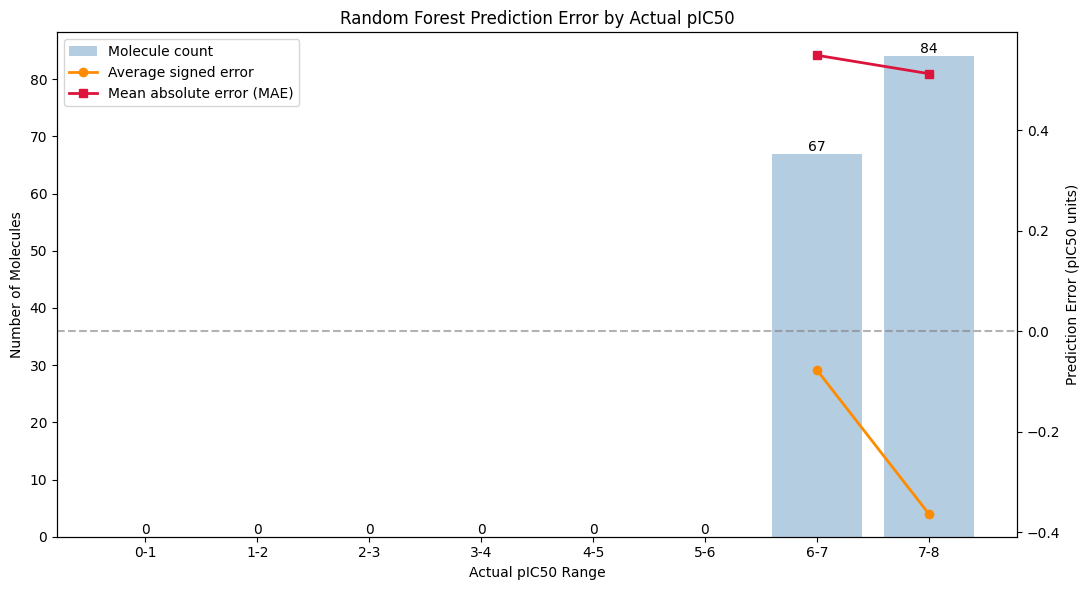

        avg_error  abs_error  count
group                              
[0, 1)        NaN        NaN      0
[1, 2)        NaN        NaN      0
[2, 3)        NaN        NaN      0
[3, 4)        NaN        NaN      0
[4, 5)        NaN        NaN      0
[5, 6)        NaN        NaN      0
[6, 7)  -0.077333   0.549035     67
[7, 8)  -0.363475   0.512419     84


In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create DataFrame from validation results
df = pd.DataFrame({
    "actual": valid.y.ravel(),
    "predicted": predictions
})

# Calculate signed error
df["error"] = df["predicted"] - df["actual"]
df["absolute"] = abs(df["predicted"] - df["actual"])

# Create bins of width 1, covering the actual pIC50 range
start = min(0, int(np.floor(df["actual"].min())))
end = int(np.floor(df["actual"].max())) + 1

bins = np.arange(start, end + 1)

df["group"] = pd.cut(
    df["actual"],
    bins=bins,
    right=False
)

# Calculate average signed error and count per group
summary = df.groupby("group", observed=False).agg(
    avg_error=("error", "mean"),
    abs_error=("absolute", "mean"),
    count=("error", "count")
)

# Plot
fig, ax1 = plt.subplots(figsize=(11, 6))

x = np.arange(len(summary))
labels = [f"{int(i.left)}-{int(i.right)}" for i in summary.index]

# Bars: number of molecules
bars = ax1.bar(
    x,
    summary["count"],
    color="steelblue",
    alpha=0.4,
    label="Molecule count"
)

ax1.set_xlabel("Actual pIC50 Range")
ax1.set_ylabel("Number of Molecules")
ax1.set_xticks(x)
ax1.set_xticklabels(labels)

# Display counts above bars
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

# Lines: prediction errors
ax2 = ax1.twinx()

ax2.plot(
    x,
    summary["avg_error"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Average signed error"
)

ax2.plot(
    x,
    summary["abs_error"],
    color="crimson",
    marker="s",
    linewidth=2,
    label="Mean absolute error (MAE)"
)

ax2.axhline(0, color="gray", linestyle="--", alpha=0.6)
ax2.set_ylabel("Prediction Error (pIC50 units)")

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left"
)

plt.title("Random Forest Prediction Error by Actual pIC50")
fig.tight_layout()
plt.show()

print(summary)

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

combined = pd.concat([
    pd.DataFrame({
        "pIC50": ds.y.ravel(),
        "split": name
    })
    for name, ds in [
        ("train", train),
        ("valid", valid),
        ("test", test)
    ]
], ignore_index=True)

print(combined.groupby("split")["pIC50"].describe())
print("\nEntire dataset:")
print(combined["pIC50"].describe())

        count      mean       std       min       25%       50%       75%  \
split                                                                       
test    152.0  6.782684  1.687206  2.698970  5.696756  7.127932  8.096910   
train  1210.0  6.420878  1.345776  2.544546  5.446756  6.585027  7.522879   
valid   151.0  7.069811  0.498339  6.251812  6.617091  7.063486  7.545222   

             max  
split             
test   10.522879  
train   9.522879  
valid   7.958607  

Entire dataset:
count    1513.000000
mean        6.521991
std         1.342417
min         2.544546
25%         5.585027
50%         6.761954
75%         7.540000
max        10.522879
Name: pIC50, dtype: float64


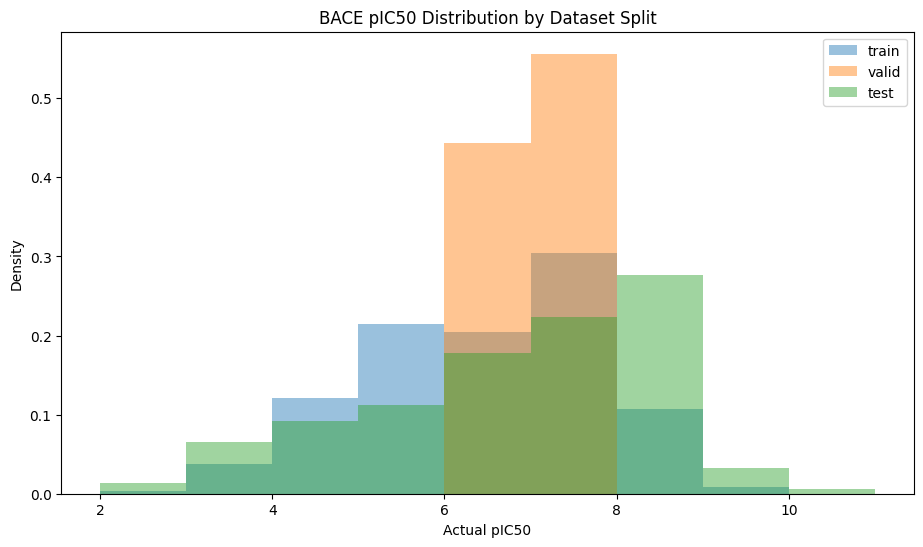

In [74]:
plt.figure(figsize=(11, 6))

bins = np.arange(
    np.floor(combined["pIC50"].min()),
    np.ceil(combined["pIC50"].max()) + 1,
    1
)

for name in ["train", "valid", "test"]:
    values = combined.loc[
        combined["split"] == name, "pIC50"
    ]

    plt.hist(
        values,
        bins=bins,
        alpha=0.45,
        density=True,
        label=name
    )

plt.xlabel("Actual pIC50")
plt.ylabel("Density")
plt.title("BACE pIC50 Distribution by Dataset Split")
plt.legend()
plt.show()

In [75]:
print(
    combined.groupby("split")["pIC50"]
    .agg(["count", "min", "max", "mean", "std"])
    .round(3)
)

       count    min     max   mean    std
split                                    
test     152  2.699  10.523  6.783  1.687
train   1210  2.545   9.523  6.421  1.346
valid    151  6.252   7.959  7.070  0.498
